## <div style="direction:rtl;text-align:right">  بخش اول؛ تحلیل و جداسازی رنگ‌ها در تصاویر دیجیتال </div>

In [28]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

<div style="direction:rtl;text-align:right">
ما برای پردازش تصویرهای ورودی از کتابخانه OpenCV استفاده کرده‌ایم پس cv2 را ایمپورت می‌کنیم.
<br/>
همچنین برای نمایش تصویرها از کتابخانه matplotlib استفاده می‌کنیم.
</div>

#### <div style="direction:rtl;text-align:right"> سوال اول؛ بررسی مشخصات تصویر </div>

In [29]:
img = cv2.imread('Peppers.png')
print('type:', type(img))
print('dimension:', img.shape)

type: <class 'numpy.ndarray'>
dimension: (1024, 1536, 3)


<div style="direction:rtl;text-align:right">
با دستور imread می‌توانیم تصویر را بخوانیم.
<br/>
تصویر در قالب یک N-dimensional Array خوانده می‌شود که یک آرایه‌ی NumPy چند بعدی از مقادیر است. 
<br/>
دستور shape تعداد خانه‌های هر بعد از آرایه را نمایش می‌دهد. این مقادیر به این معنی است که تصویر ما دارای طول و عرض 1024 در 1536 پیکسلی است و 3 کانال رنگی RGB دارد.
<br/>
اگر تصویر خوانده شده را مستقیما با matplotlib نمایش دهیم، تصویری مانند تصویر سمت چپ خواهیم داشت که از نظر رنگی درست نیست.
</div>

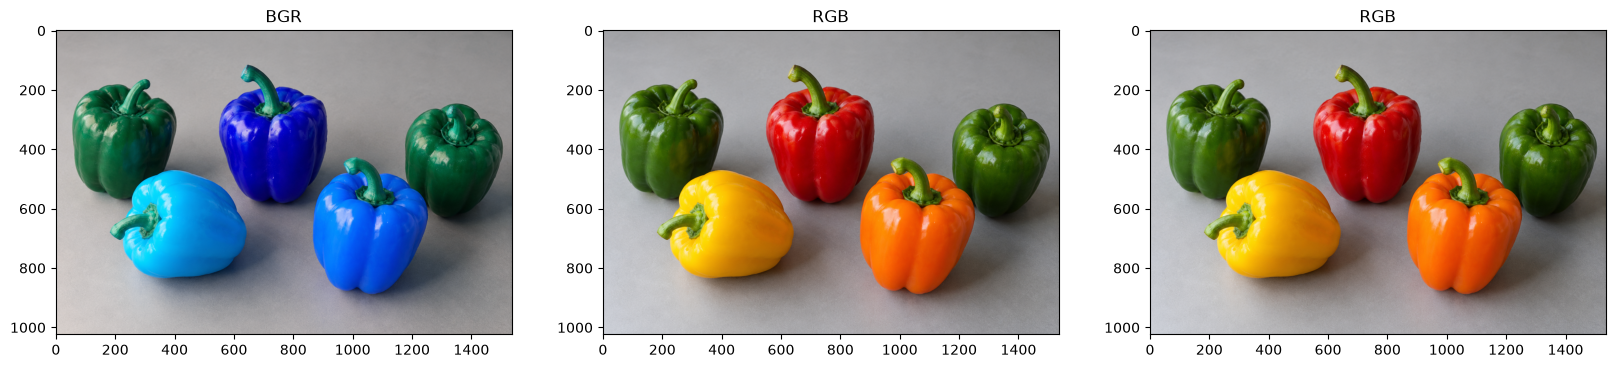

In [30]:
plt.figure(figsize=[20,5])
plt.subplot(131); plt.imshow(img); plt.title("BGR");

plt.subplot(132); plt.imshow(img[:,:,::-1]); plt.title("RGB"); # برعکس کردن ترتیب کانال‌ها

img2 = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # استفاده از تابع آماده
plt.subplot(133); plt.imshow(img2); plt.title("RGB");

<div style="direction:rtl;text-align:right">
دلیل این اتفاق این است که OpenCV به طور پیش فرض تصاویر را بصورت BGR می‌خواند. اما matplotlib ترتیب کانال‌های تصاویر را RGB رسم می‌کند.
<br/>
بنابراین اگر مستقیما همان تصویر را نمایش دهیم،‌ جای کانال‌های R و B جابجا خواهد بود و رنگ‌بندی تصویر متفاوت می‌شود.
<br/>
برای نمایش درست تصویر باید ترتیب کانال‌های رنگی را جابجا کنیم. می‌توانیم بصورت دستی کانال‌های ورودی را برعکس به matplotlib بدهیم یا از توابع داخلی OpenCV استفاده کنیم.
</div>

In [31]:
B, G, R = cv2.split(img)
print('Red:\t min:', R.min(), '\tmax:', R.max())
print('Green:\t min:', G.min(), '\tmax:', G.max())
print('Blue:\t min:', B.min(), '\tmax:', B.max())

Red:	 min: 0 	max: 255
Green:	 min: 0 	max: 253
Blue:	 min: 0 	max: 229


<div style="direction:rtl;text-align:right">
برای دیدن محدوده مقادیر هر کانال، هر کانال رنگی را بطور جداگانه ذخیره کردیم تا بتوانیم مقدار مینیمم و ماکسیمم هر کدام را جداگانه نمایش دهیم.
<br/>
با استفاده از تابع داخل min و max پایتون، کمترین و بیشترین مقدار هر کانال رنگی را بدست آورده‌ایم.
</div>

#### <div style="direction:rtl;text-align:right"> سوال دوم؛ تبدیل انواع تصاویر </div>

<div style="direction:rtl;text-align:right">تصویر ورودی را به سه حالت RGB، Grayscale و Binary تبدیل می‌کنیم.</div>

In [66]:
# 1) RGB
RGB_img = img[:,:,::-1]

# 2) Grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 3) Binary
threshold, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print("Threshold value:", threshold)

Threshold value: 116.0


<div style="direction:rtl;text-align:right">

##### روش تولید تصویر دودویی و آستانه
- از **آستانه‌گذاری Otsu** استفاده شد. این روش آستانه را خودکار و از روی هیستوگرام انتخاب می‌کند، به‌طوری که واریانس بین دو دسته (پیکسل‌های تیره و روشن) بیشینه شود.
- مقدار آستانه انتخاب‌شده در خروجی چاپ شده است (پیکسل‌های بزرگ‌تر از آستانه ۲۵۵ و بقیه ۰ می‌شوند).
- دلیل انتخاب: نیازی به حدس زدن دستی آستانه (مثلاً ۱۲۷) نیست و به شرایط روشنایی خود تصویر وابسته است.

##### چه اطلاعاتی از دست می‌رود؟
##### رنگی ← خاکستری:
- اطلاعات رنگ (Hue و Saturation) از بین می‌رود و سه کانال به یک کانال تبدیل می‌شود (فقط شدت روشنایی می‌ماند، طبق رابطه Gray = 0.299R + 0.587G + 0.114B).
- رنگ‌های متفاوتی که روشنایی مشابه دارند (مثلاً فلفل قرمز و سبز) ممکن است خاکستری یکسان یا نزدیک بگیرند و تفکیک‌شان سخت شود.

##### خاکستری ← دودویی:
- از ۲۵۶ سطح روشنایی فقط دو سطح (۰ و ۲۵۵) می‌ماند، پس سایه‌روشن‌ها، گرادیان‌ها و حس عمق/حجم از بین می‌رود.
- جزئیات ظریف و بافت (Texture) حذف می‌شود و نتیجه به مقدار آستانه حساس است.

##### این تبدیل‌ها بازگشت‌ناپذیرند و از روی تصویر دودویی نمی‌توان تصویر رنگی اصلی را بازسازی کرد.</div>

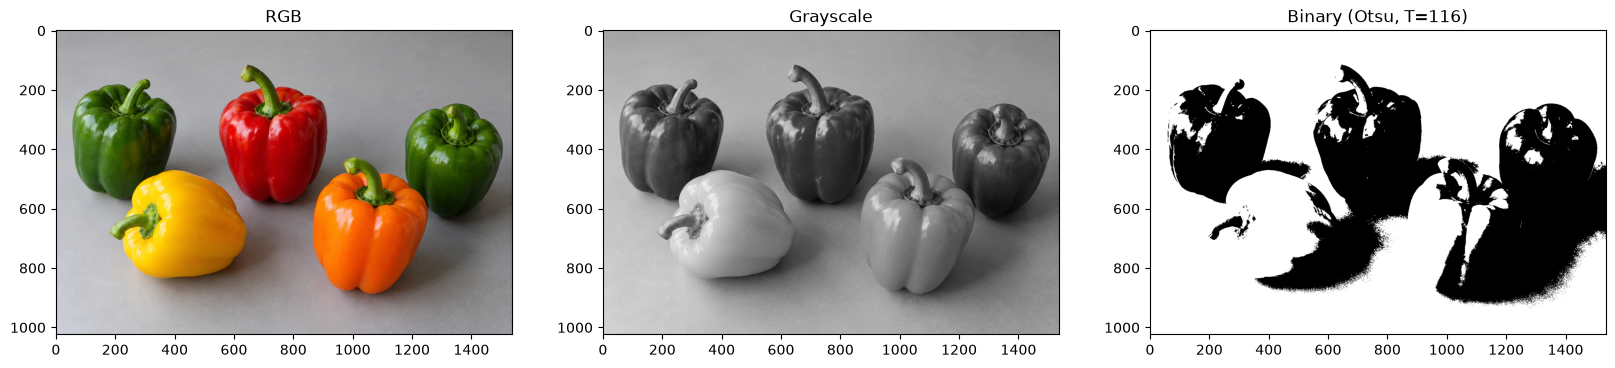

In [68]:
plt.figure(figsize=[20,5])
plt.subplot(131); plt.imshow(RGB_img); plt.title("RGB");
plt.subplot(132); plt.imshow(gray, cmap="gray"); plt.title("Grayscale");
plt.subplot(133); plt.imshow(binary, cmap="gray"); plt.title(f"Binary (Otsu, T={threshold:.0f})");

#### <div style="direction:rtl;text-align:right"> سوال سوم؛ بررسی فضاهای رنگی RGB و HSV </div>

<div style="direction:rtl;text-align:right">
برای تفکیک کانال‌های رنگی تصویر RGB کافیست در هر مرحله فقط یکی از ابعاد تصویر را نمایش دهیم.
    <br/>
در تصاویر هر کانال، نقاطی که تیره تر هستند، یعنی مقدار کمتری دارند و رنگ مد نظر در آن نقطه کمتر است. همچنین نقاط روشن تر مقادیر بیشتر هستند و رنگ بیشتری از آن کانال رنگی خاص در آن نقطه وجود دارد.
    <br/>
مثلا در کانال Blue می‌بینیم که نقاط روی فلفل‌ها بسیار تیره است. این یعنی مقدار رنگ آبی در این نقاط بسیار کم است که با تصویر اصلی نیز همخوانی دارد.
</div>

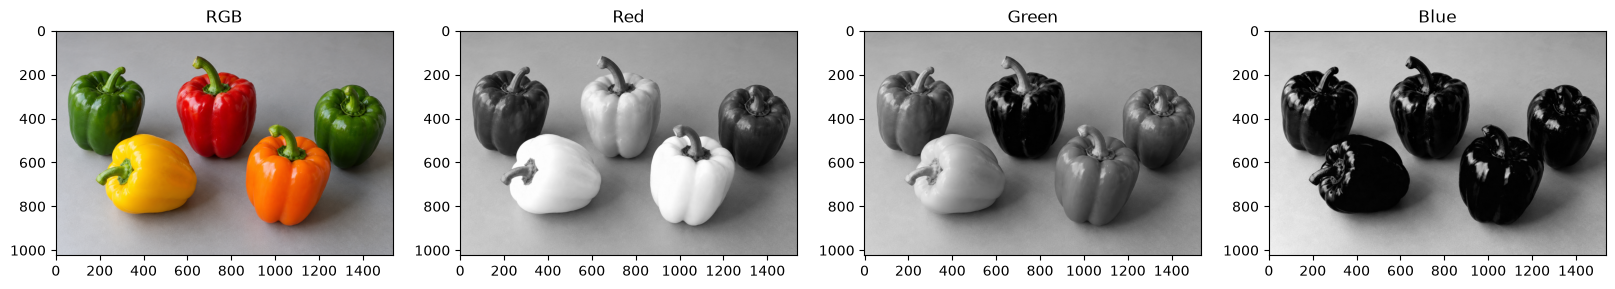

In [35]:
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=[20,8])
plt.subplot(141); plt.imshow(RGB_img); plt.title("RGB");
plt.subplot(142); plt.imshow(RGB_img[:,:,0], cmap='gray'); plt.title("Red");
plt.subplot(143); plt.imshow(RGB_img[:,:,1], cmap='gray'); plt.title("Green");
plt.subplot(144); plt.imshow(RGB_img[:,:,2], cmap='gray'); plt.title("Blue");

<div style="direction:rtl;text-align:right">
برای تبدیل تصویر به HSV از تابع داخلی OpenCV استفاده کردیم. باید توجه داشت که وقتی تصویر را به HSV تبدیل می‌کنیم، دیگر با matplotlib قابل رسم نیست چرا که matplotlib‌ فقط RGB می‌پذیرد. بنابراین اگر تصویر HSV را به matplotlib بدهیم، تصویر سمت چپ را خواهیم داشت که رنگ بندی درستی ندارد چرا که ابعاد تصویر اصلا مقادیر RGB نیستند اما matplotlib آنها را بعنوان RGB می‌خواند.
    <br/>
هر یک از کانال‌ها HSV به طور جداگانه رسم شده‌اند. مانند تصاویر قبلی، نقاط تیره تر به معنی مقدار کمتر و نقاط روشن تر مقادیر بیشتر هستند.
    <br/>
مثلا نقاط روی فلفل‌ها که نقاط رنگی تصویر هستند، دارای Saturation بالا هستند. سایر نقاط تصویر که غالبا خاکستری‌اند، مقدار Sqturation پایین و نزدیک به صفری دارند که با تصویر اصلی نیز همخوانی دارد.
    </div>

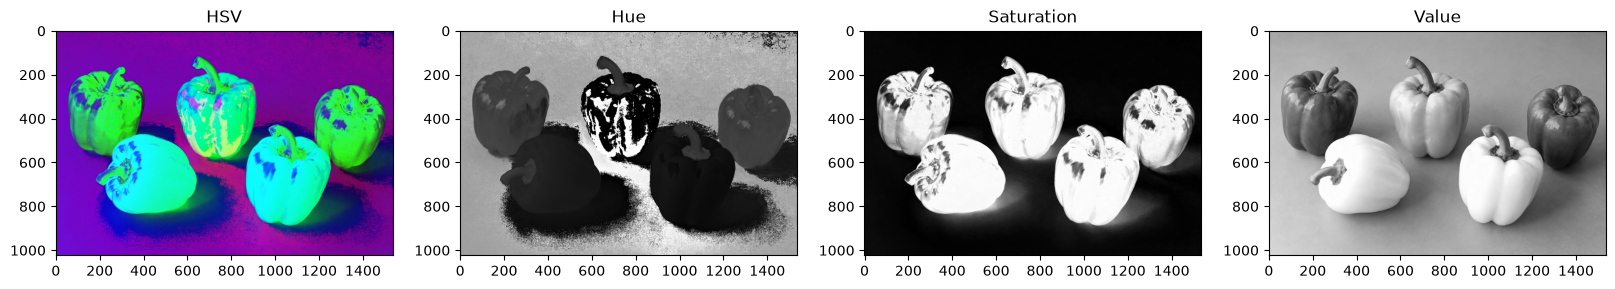

In [36]:
HSV_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

plt.figure(figsize=[20,8])
plt.subplot(245); plt.imshow(HSV_img); plt.title("HSV");
plt.subplot(246); plt.imshow(HSV_img[:,:,0], cmap='gray'); plt.title("Hue");
plt.subplot(247); plt.imshow(HSV_img[:,:,1], cmap='gray'); plt.title("Saturation");
plt.subplot(248); plt.imshow(HSV_img[:,:,2], cmap='gray'); plt.title("Value");

<div style="direction:rtl;text-align:right">
در فضای رنگی RGB، تصاویر در قالب سه کانال رنگی اصلی نور ذخیره می‌شوند. در این فضا، اطلاعات رنگ و روشنایی تصویر با یکدیگر ترکیب شده‌اند و معمولا تغییر روشنایی تصویر، باعث ایجاد تغییر در هر سه کانال می‌شود. در فضای رنگی RGB برای تشخیص رنگ هر نقطه از تصویر، به هر سه کانال نیاز داریم.
</div>

<div style="direction:rtl;text-align:right">
در فضای رنگی HSV، تصویر در قالب سه مقدار فام رنگ (Hue)، غلظت یا شدت رنگ (Saturation) و میزان روشنایی (Value) ذخیره می‌شود. در این فضای رنگی، مقدار رنگ از اطلاعات مربوط به روشنایی جدا شده که امکان بررسی رنگ اجسام با تمرکز فقط بر کانال Hue را می‌دهد. بنابراین فضای رنگی HSV برای تفکیک و بررسی رنگ اجسام مناسب تر است زیرا مؤلفه Hue امکان شناسایی نوع رنگ را بدون وابستگی مستقیم به شدت روشنایی فراهم می‌کند.
</div>

<div style="direction:rtl;text-align:right">
برای مثال، اگر بخواهیم تمام اجسام قرمز موجود در یک تصویر را شناسایی کنیم، در فضای HSV می‌توانیم محدوده مشخصی از Hue را انتخاب کنیم و با استفاده از Saturation و Value نیز رنگ‌های کم‌اشباع یا بسیار تاریک را حذف کنیم.
در مقابل، در فضای RGB تشخیص یک رنگ خاص، نیازمند بررسی هر سه کانال رنگی و تعیین روابط بین آنهاست..</div>

#### <div style="direction:rtl;text-align:right"> سوال چهارم؛ جداسازی نواحی رنگی </div>

<img src="HSV_color_mode.png" />

<div style="direction:rtl;text-align:right">
برای جداسازی رنگ سبز در تصویر، از فضای رنگی HSV استفاده می‌کنیم زیرا در این فضای رنگی، اطلاعات رنگ را بصورت جداگانه داریم و میتوانیم حدود رنگ‌ها را راحت تر مشخص کنیم.
<br/>
طبق تصویر بالا، مقادیری از Hue که شامل رنگ سبز هستند تقریبا مشخص است. در این نواحی، مقادیری از saturation و value که مقدار پایینی دارند را حذف می‌کنیم چراکه رنگ‌های خیلی روشن یا خیلی تیره به ما می‌دهند که مطلوب نیست.
<br/>
بنابراین بازه‌ی مقادیری از H، S و V را که پیش بینی می‌کنیم در برگیرنده رنگ سبز هستند را انتخاب و از تصویر اصلی جدا می‌کنیم. 
</div>

In [63]:
def colorDetection(start, end, image):
    start = np.array(start)
    end = np.array(end)
    mask = cv2.inRange(image, start, end)

    return mask

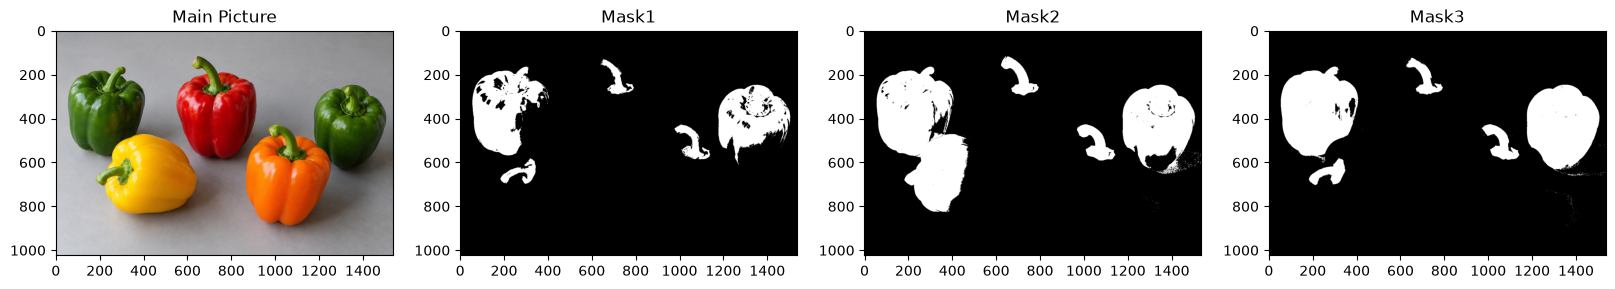

In [71]:
#                        [H,  S,  V]   [H,  S,  V]
mask_1 = colorDetection([35, 50, 50], [85, 255, 255], HSV_img)
mask_2 = colorDetection([20, 30, 30], [85, 255, 255], HSV_img)
mask_3 = colorDetection([30, 10, 10], [85, 255, 255], HSV_img)

plt.figure(figsize=[20,8])
plt.subplot(141); plt.imshow(RGB_img); plt.title("Main Picture");
plt.subplot(142); plt.imshow(mask_1, cmap='gray'); plt.title("Mask1");
plt.subplot(143); plt.imshow(mask_2, cmap='gray'); plt.title("Mask2");
plt.subplot(144); plt.imshow(mask_3, cmap='gray'); plt.title("Mask3");

<div style="direction:rtl;text-align:right">
برای انتخاب بهتر نواحی سبز تصویر، چند بازه‌ی مختلف از مقادیر را امتحان کردیم.
<br/>
همانطور که مشخص است در تصویر سمت راست نیز که تقریبا بهترین تشخیص را دارد، هنوز هم ناحیه‌هایی از سبزهای تصویر وجود دارند که ماسک نشده‌اند و ناحیه‌هایی هم وجود دارند که اضافی ماسک شده‌اند.
<br/>
مثلا قسمت‌هایی از فلفل‌های سبز رنگ که خیلی تیره و نزدیک به سیاه بوده‌اند انتخاب نشده‌اند و از طرفی قسمت‌هایی از پس زمینه‌ی تصویر، چون در بازه‌ی انتخابی ما قرار داشته‌اند انتخاب شده‌اند.
    <br/>
همچنین برای درک راحت تر نواحی انتخاب شده، تصاویر بصورت سیاه و سفید رسم شده‌اند.
    <br/>
حالا برای اعمال ماسک‌های فوق روی تصوی اصلی، کافیست ماسک‌ها را با تصویرمان and کنیم. در اینصورت نواحی سیاه ماسک که مثابه 0 هستند، نواحی متناظر در تصویر اصلی را 0 و سیاه می‌کنند.
    <br/>
همچنین نواحی از ماسک که سفید هستند به مثابه 1 منطقی‌اند و نواحی متناظر در تصویر اصلی را حفظ می‌کنند. نتیجه در تصاویر زیر مشخص شده است.
</div>

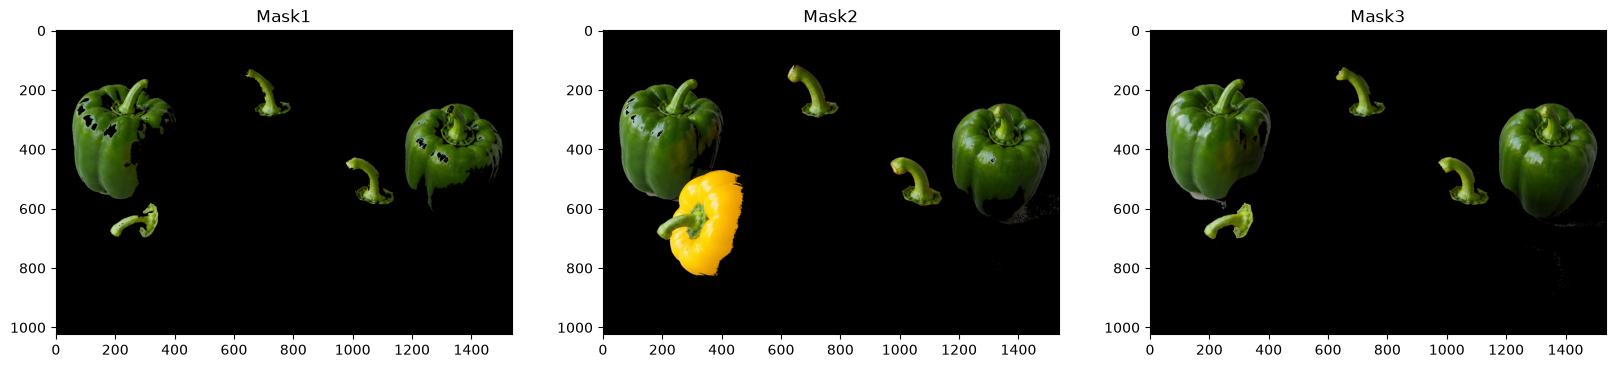

In [38]:
result_1 = cv2.bitwise_and(RGB_img, RGB_img, mask=mask_1)
result_2 = cv2.bitwise_and(RGB_img, RGB_img, mask=mask_2)
result_3 = cv2.bitwise_and(RGB_img, RGB_img, mask=mask_3)

plt.figure(figsize=[20,5])
plt.subplot(131); plt.imshow(result_1); plt.title("Mask1");
plt.subplot(132); plt.imshow(result_2); plt.title("Mask2");
plt.subplot(133); plt.imshow(result_3); plt.title("Mask3");

#### <div style="direction:rtl;text-align:right"> سوال پنجم؛ بررسی هیستوگرام و کنتراست </div>

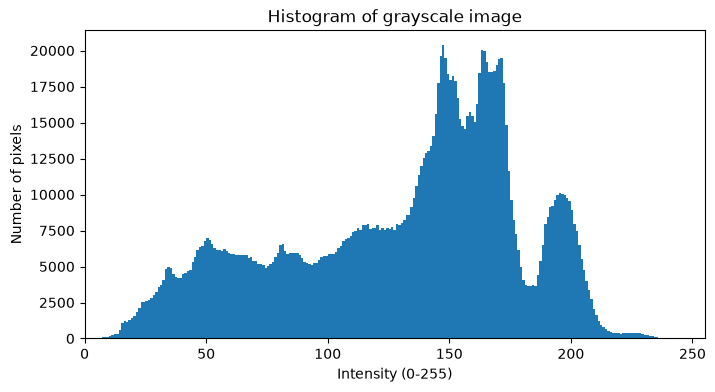

In [39]:
plt.figure(figsize=(8, 4))
plt.hist(gray.ravel(), bins=256, range=(0, 256))
plt.title("Histogram of grayscale image")
plt.xlabel("Intensity (0-255)")
plt.ylabel("Number of pixels")
plt.xlim(0, 255)
plt.show()

In [73]:
def rms_contrast(image):
    I = image.astype(np.float32) / 255.0
    return np.sqrt(np.mean((I - I.mean()) ** 2))

print(f"RMS contrast of original image: {rms_contrast(gray):.4f}")

RMS contrast of original image: 0.1906


In [74]:
def change_contrast(image, alpha):
    mean = image.mean()
    out = mean + alpha * (image.astype(np.float32) - mean)
    return np.clip(out, 0, 255).astype(np.uint8)

high_contrast = change_contrast(gray, alpha=1.5)
low_contrast  = change_contrast(gray, alpha=0.5)

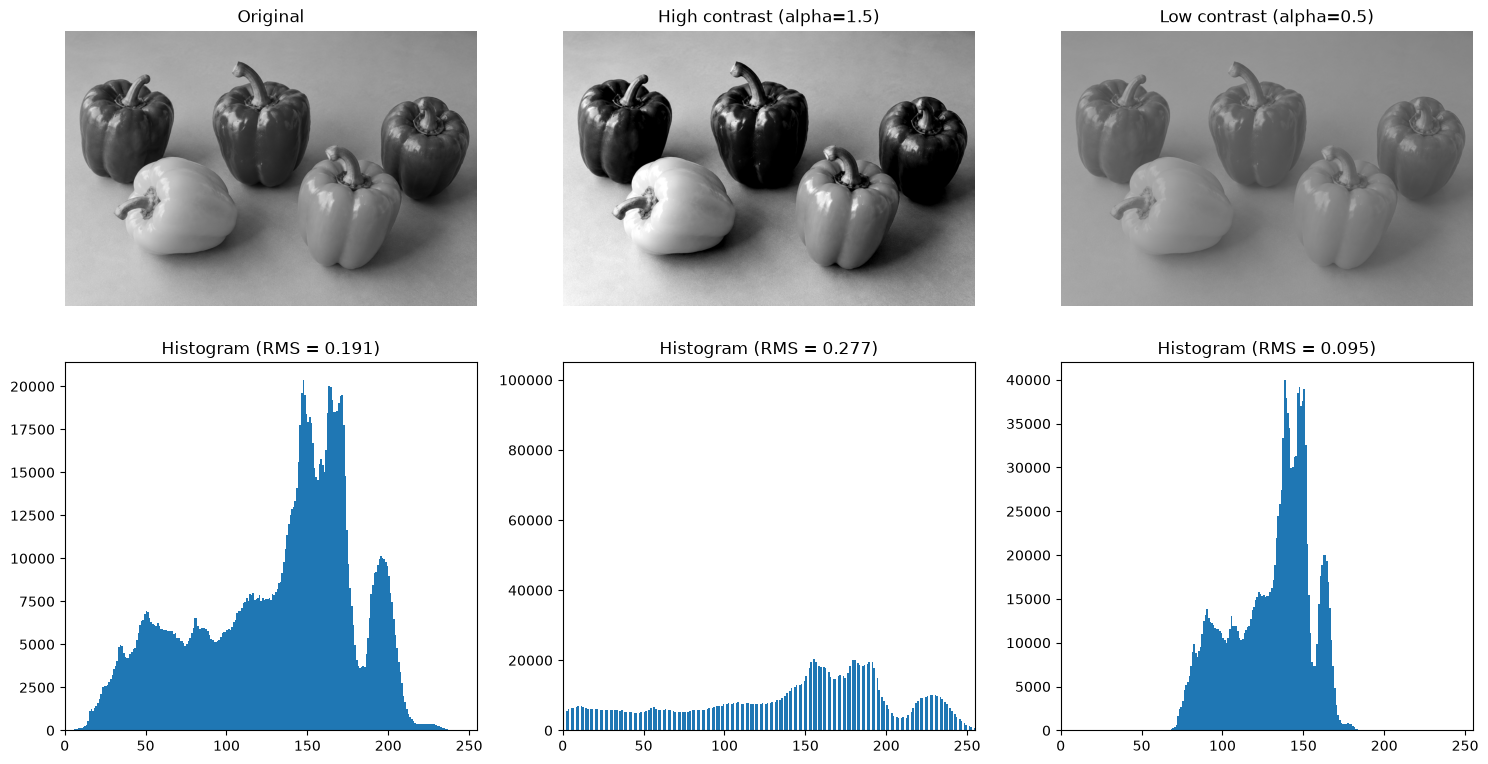

In [76]:
images = [
    ("Original", gray),
    ("High contrast (alpha=1.5)", high_contrast),
    ("Low contrast (alpha=0.5)", low_contrast),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, (title, im) in enumerate(images):

    axes[0, i].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title(title)
    axes[0, i].axis("off")

    axes[1, i].hist(im.ravel(), bins=256, range=(0, 256))
    axes[1, i].set_xlim(0, 255)
    axes[1, i].set_title(f"Histogram (RMS = {rms_contrast(im):.3f})")

plt.tight_layout()
plt.show()

In [43]:
base = rms_contrast(gray)

print(f"{'Image':28s} {'Mean':>8s} {'RMS':>8s} {'Change vs original':>20s}")
for title, im in images:
    rms = rms_contrast(im)
    change = (rms - base) / base * 100
    print(f"{title:28s} {im.mean():8.1f} {rms:8.4f} {change:+19.1f}%")

Image                            Mean      RMS   Change vs original
Original                        130.3   0.1906                +0.0%
High contrast (alpha=1.5)       130.7   0.2769               +45.3%
Low contrast (alpha=0.5)        129.9   0.0953               -50.0%


<div style="direction:rtl;text-align:right">

##### توزیع شدت روشنایی
<div style="direction:rtl;text-align:right"> هیستوگرام تصویر اصلی نشان می‌دهد پیکسل‌ها بیشتر در محدوده میانی متمرکز هستند. مقدار RMS Contrast تصویر اصلی برابر 0.19 است.
    </div>

##### روش تغییر کنتراست
<div style="direction:rtl;text-align:right"> از رابطه `out = mean + alpha * (I - mean)` استفاده شد. این رابطه پیکسل‌ها را حول میانگین کشش (alpha>1) یا فشرده (alpha<1) می‌کند و میانگین روشنایی تقریباً ثابت می‌ماند، پس فقط کنتراست تغییر می‌کند و نه روشنایی کلی.
    </div>

##### مقایسه
| تصویر | RMS | تغییر نسبت به اصلی |
|---|---|---|
| اصلی | 0.19 | 00% |
| پرکنتراست (α=1.5) | 0.28 | 45% |
| کم‌کنتراست (α=0.5) | 0.095 | -50% |

- در نسخه **کم‌کنتراست**، هیستوگرام باریک‌تر و دور میانگین فشرده شده و RMS دقیقاً حدود نصف شده است (به دلیل α=0.5).
- در نسخه **پرکنتراست**، هیستوگرام پهن‌تر می‌شود و RMS افزایش می‌یابد. چون مقادیر بیرون از بازه [0,255] برش (clip) می‌خورند، افزایش کمی کمتر از ۱.۵ برابر است و ممکن است روی دو لبه هیستوگرام (۰ و ۲۵۵) یک ستون بلند ببینیم.

</div>

#### <div style="direction:rtl;text-align:right"> سوال ششم؛ بهبود تصویر در شرایط نوری نامناسب </div>

<div style="direction:rtl;text-align:right">
برای کاهش نور مصنوعی تصویر از دو روش متفاوت استفاده کردیم.
<br/>
در روش اول از تمامی مقادیر کانال value تصویر یک مقدار ثابت کم کردیم تا روشنایی تصویر کاهش پیدا کند. در اینصورت پیکسل‌هایی که مقادیر value کمتر از 70 داشتند به 0 و سیاه تبدیل شدند.
<br/>
در روش دوم برای جلوگیری از سیاه شدن پیکسل‌ها، تمامی مقادیر کانال value را در یک عدد کوچکتر از 1 ضرب کردیم. در اینصورت پیکسل‌هایی که از قبل مقداری روشنایی داشتند دیگر 0 نخواهند شد.
</div>

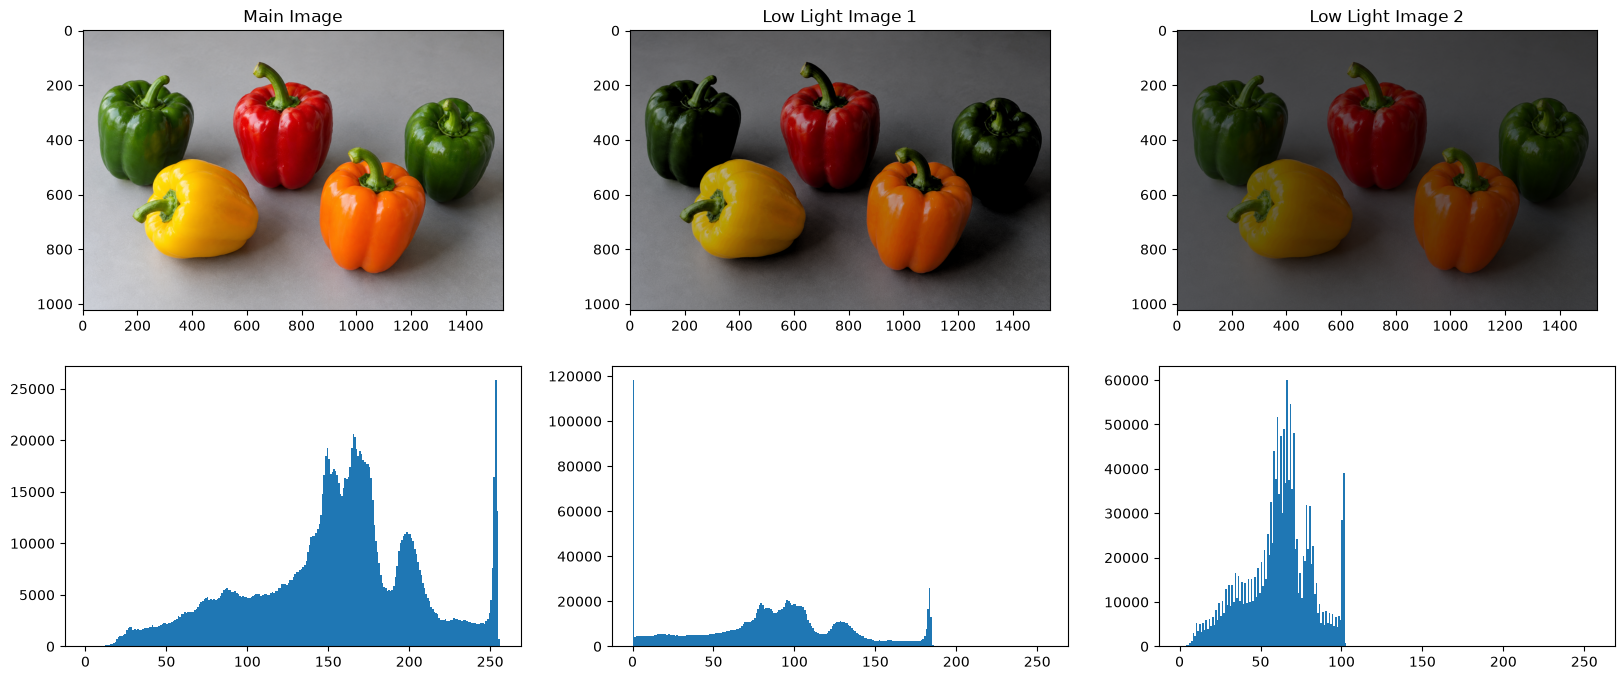

In [61]:
lowLight_img1 = HSV_img.copy()
lowLight_img1[:,:,2] = cv2.subtract(lowLight_img1[:, :, 2], 70)

lowLight_img2 = HSV_img.copy()
lowLight_img2[:,:,2] = (lowLight_img2[:, :, 2] * 0.4).astype(np.uint8)

plt.figure(figsize=[20,8])
plt.subplot(231); plt.imshow(RGB_img); plt.title('Main Image');
plt.subplot(232); plt.imshow(cv2.cvtColor(lowLight_img1, cv2.COLOR_HSV2RGB)); plt.title('Low Light Image 1');
plt.subplot(233); plt.imshow(cv2.cvtColor(lowLight_img2, cv2.COLOR_HSV2RGB)); plt.title('Low Light Image 2');

plt.subplot(234); plt.hist(HSV_img[:,:,2].ravel(), bins=256, range=(0, 256));
plt.subplot(235); plt.hist(lowLight_img1[:,:,2].ravel(), bins=256, range=(0, 256));
plt.subplot(236); plt.hist(lowLight_img2[:,:,2].ravel(), bins=256, range=(0, 256));

<div style="direction:rtl;text-align:right">
OpneCV تابع آماده‌ی اصلاح نور تصویر به روش Histogram Equlization را دارد.
<br/>
در این روش و روش بعدی، اصلاحات را فقط روی کانال value اعمال کردیم. چرا که هدف فقط تغییر روشنایی تصویر است و در اینصورت رنگ‌های موجود در تصویر دست نخورده باقی می‌مانند.
<br/>
روش زیر تلاش می‌کند تا یک نگاشت غیرخطی بین روشنایی تصویر ورودی و خروجی ایجاد کند. 
</div>

##### <div style="direction:rtl;text-align:right"> Histogram Equalization </div>

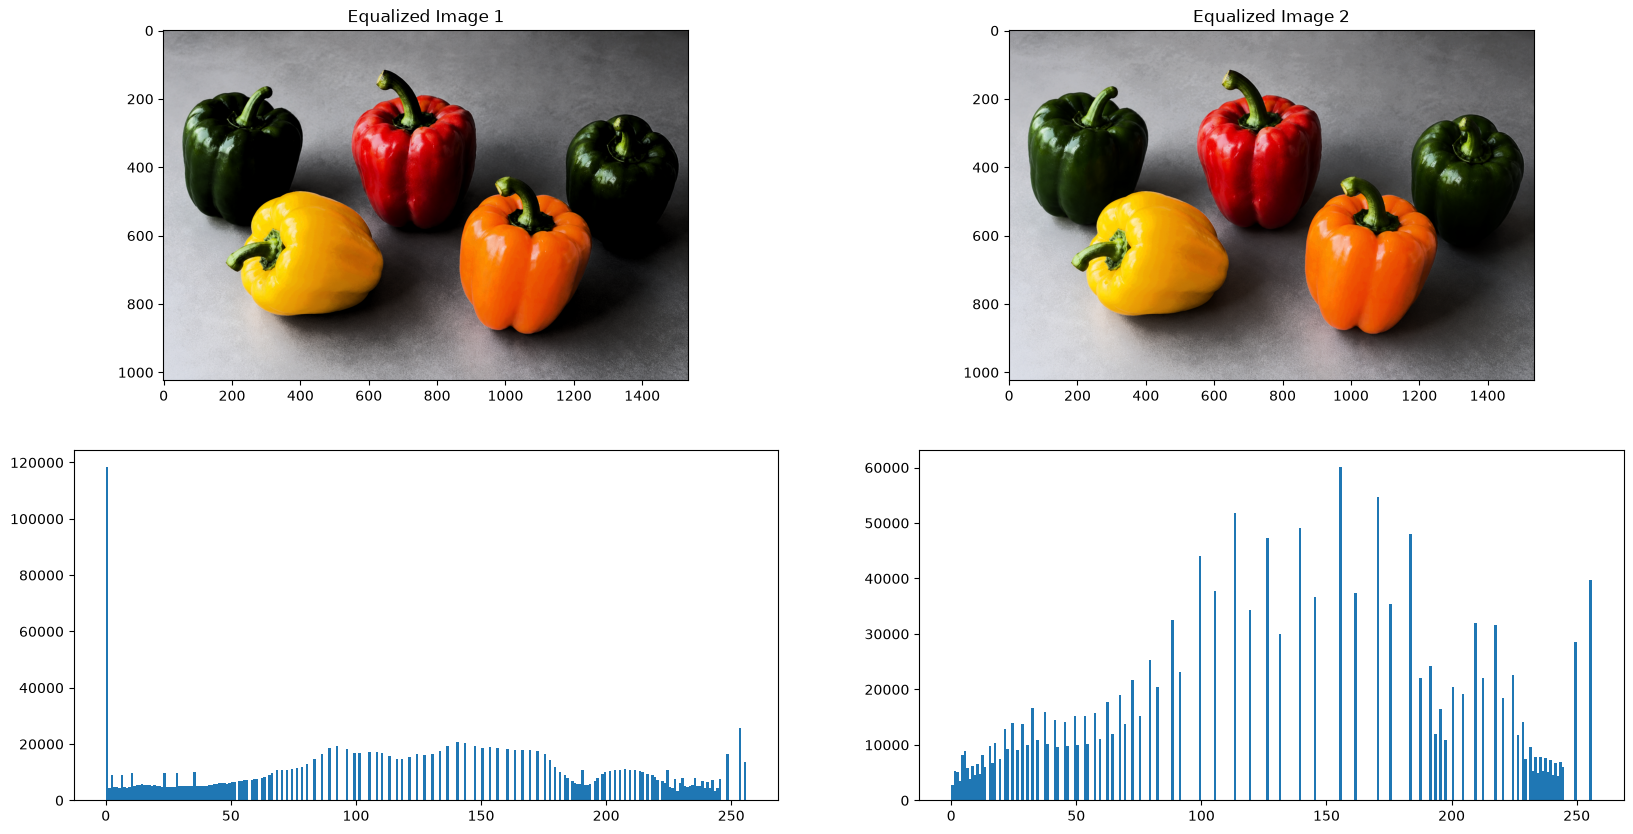

In [58]:
h1, s1, value_channel_1 = cv2.split(lowLight_img1)
equalized_value_1 = cv2.equalizeHist(value_channel_1)
equalized_img1 = cv2.merge([h1, s1, equalized_value_1])

h2, s2, value_channel_2 = cv2.split(lowLight_img2)
equalized_value_2 = cv2.equalizeHist(value_channel_2)
equalized_img2 = cv2.merge([h2, s2, equalized_value_2])

plt.figure(figsize=[20,10])
plt.subplot(221); plt.imshow(cv2.cvtColor(equalized_img1, cv2.COLOR_HSV2RGB)); plt.title('Equalized Image 1');
plt.subplot(222); plt.imshow(cv2.cvtColor(equalized_img2, cv2.COLOR_HSV2RGB)); plt.title('Equalized Image 2');

plt.subplot(223); plt.hist(equalized_value_1.ravel(), bins=256, range=(0, 256));
plt.subplot(224); plt.hist(equalized_value_2.ravel(), bins=256, range=(0, 256));

<div style="direction:rtl;text-align:right">
روش Histogram Stretching بازه‌ی شدت روشنایی تصویر را در کل محدوده 0 تا 255 گسترش می‌دهد. این کار بر اساس رابطه‌ی زیر انجام می‌شود؛
<div style="direction:rtl;text-align:left"> V_new = (V_old - V_min) / (V_max - V_min) * 255 </div>
پس از اصلاح، کمترین میزان روشنایی به صفر، و بیشترین میزان روشنایی به 255 نگاشت می‌یابد. همچنین سایر مقادیر نیز به نسبت و بصورت خطی تبدیل می‌شوند. 
    <br/>
    در واقع توزیع هیستوگرام تصویر را کشیده و پخش می‌کند.
</div>

##### <div style="direction:rtl;text-align:right"> Histogram Stretching </div>

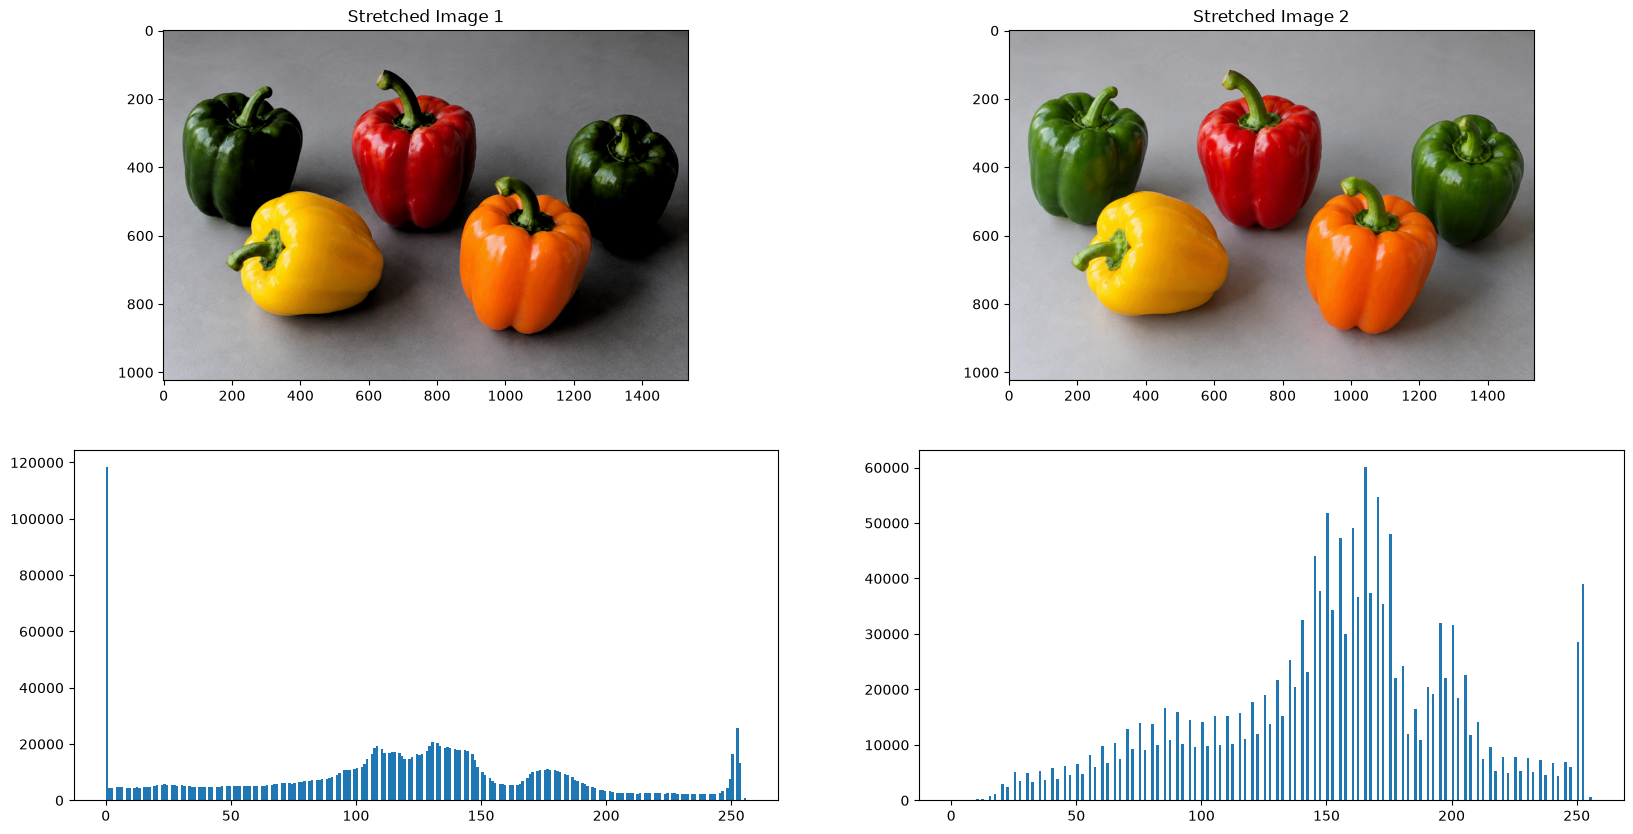

In [62]:
min_value_1 = np.min(value_channel_1); max_value_1 = np.max(value_channel_1);
stretched_value_1 = ((value_channel_1 - min_value_1) / (max_value_1 - min_value_1) * 255).astype(np.uint8)
stretched_img1 = cv2.merge([h1, s1, stretched_value_1])

min_value_2 = np.min(value_channel_2); max_value_2 = np.max(value_channel_2);
stretched_value_2 = ((value_channel_2 - min_value_2) / (max_value_2 - min_value_2) * 255).astype(np.uint8)
stretched_img2 = cv2.merge([h2, s2, stretched_value_2])

plt.figure(figsize=[20,10])
plt.subplot(221); plt.imshow(cv2.cvtColor(stretched_img1, cv2.COLOR_HSV2RGB)); plt.title('Stretched Image 1');
plt.subplot(222); plt.imshow(cv2.cvtColor(stretched_img2, cv2.COLOR_HSV2RGB)); plt.title('Stretched Image 2');

plt.subplot(223); plt.hist(stretched_value_1.ravel(), bins=256, range=(0, 256));
plt.subplot(224); plt.hist(stretched_value_2.ravel(), bins=256, range=(0, 256));

#### <div style="direction:rtl;text-align:right"> سوال هفتم؛ بررسی تاثیر بهبود تصویر بر جداسازی رنگ </div>

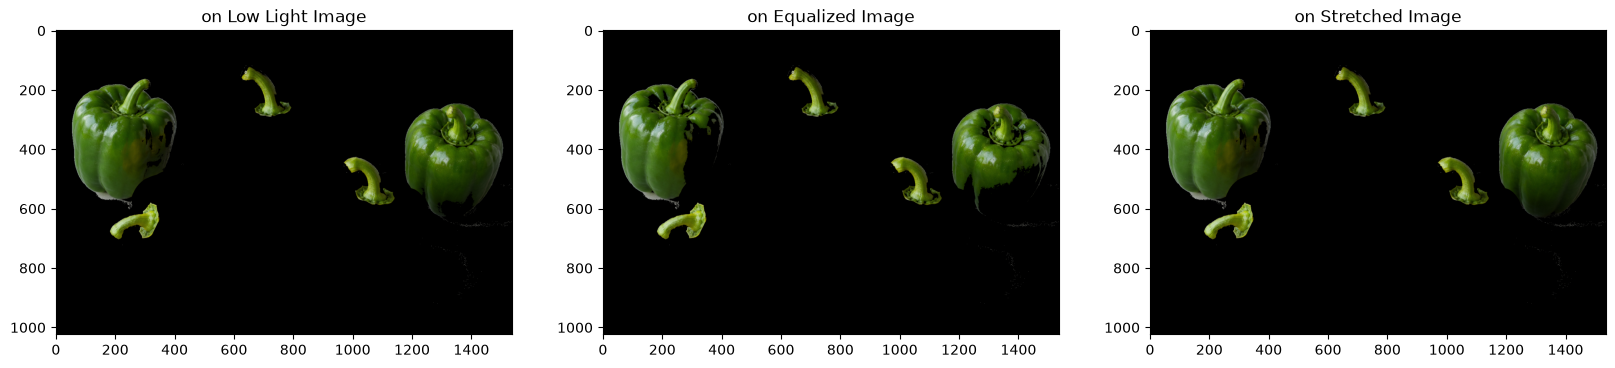

In [65]:
mask_1 = colorDetection([30, 10, 10], [85, 255, 255], lowLight_img2)
result_1 = cv2.bitwise_and(RGB_img, RGB_img, mask=mask_1)

mask_2 = colorDetection([30, 10, 10], [85, 255, 255], equalized_img2)
result_2 = cv2.bitwise_and(RGB_img, RGB_img, mask=mask_2)

mask_3 = colorDetection([30, 10, 10], [85, 255, 255], stretched_img2)
result_3 = cv2.bitwise_and(RGB_img, RGB_img, mask=mask_3)

plt.figure(figsize=[20,5])
plt.subplot(131); plt.imshow(result_1); plt.title("on Low Light Image");
plt.subplot(132); plt.imshow(result_2); plt.title("on Equalized Image");
plt.subplot(133); plt.imshow(result_3); plt.title("on Stretched Image");

<div style="direction:rtl;text-align:right">
واضح است که کاهش روشنایی تصویر، بر جداسازی تمیزتر رنگ‌های اثر منفی می‌گذارد چراکه مقادیر پیکسل‌ها را به یکدیگر نزدیک‌تر می‌کند.
    <br/>
اما در خصوص تصاویر بهبود یافته، تصویری که با روش Histogram Equalization اصلاح شده نتیجه‌ی بدتری دارد. در این تصویر برخی نقاط سبز رنگ به سمت سیاهی رفته و انتخاب نشده‌اند.
    <br/>
از طرفی تصویر بهبود یافته با روش Histogram Stretching وضعیت مطلوبی دارد. در این تصویر محدوده‌ی تشخیص داده شده اگرچه کامل نیست اما به نسبت بهتر و قابل قبول است.
</div>